<a href="https://colab.research.google.com/github/Maram1423/purchase-intent-predictor/blob/main/Copy_of_Purchase_Intent_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Will This Visitor Buy? Purchase Intent Prediction
**NextGen Institute · Machine Learning Final Project**

## 1. Problem framing
- **Who has the problem:** an online store where most visitors leave without buying.
- **Decision the model supports:** show a coupon or a chat assistant only to visitors who are unlikely to buy on their own, instead of giving discounts to everyone.
- **Target:** `Revenue` (1 = the session ended in a purchase, 0 = no purchase).
- **Metric:** ROC-AUC to compare models, and **Recall / Precision of the buyer class** to choose the threshold. Accuracy is not used because the data is imbalanced (a model that always says "no purchase" would already look accurate).
- **Dataset:** Online Shoppers Purchasing Intention, UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/468

> **Colab:** run the next cell once to install the dataset downloader.

In [1]:
!pip install -q ucimlrepo scikit-learn==1.9.1

In [2]:
import json, joblib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, precision_score, recall_score, f1_score,
                             average_precision_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Data understanding

In [3]:
from ucimlrepo import fetch_ucirepo
ds = fetch_ucirepo(id=468)
df = pd.concat([ds.data.features, ds.data.targets], axis=1)

# If the download fails, upload the CSV manually and use this instead:
# df = pd.read_csv("online_shoppers_intention.csv")

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [5]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().sum().sum() else "None")
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass balance:")
print(df["Revenue"].value_counts())
print(df["Revenue"].value_counts(normalize=True).round(3))

Missing values per column:
None

Duplicate rows: 125

Class balance:
Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    0.845
True     0.155
Name: proportion, dtype: float64


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


**Column dictionary**

| Column | Meaning |
|---|---|
| `Administrative`, `Informational`, `ProductRelated` | Number of pages visited of each type in the session |
| `*_Duration` | Seconds spent on each page type |
| `BounceRates` | Share of visitors who leave after one page (Google Analytics) |
| `ExitRates` | Share of views of a page that were the last in the session |
| `PageValues` | Average value of the pages visited before a purchase |
| `SpecialDay` | Closeness of the visit to a special day (e.g. Valentine's), 0 to 1 |
| `Month`, `Weekend` | When the visit happened |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | Technical / geographic IDs (categorical codes) |
| `VisitorType` | New, Returning or Other |
| `Revenue` | **Target**: purchase or not |

The dataset has no missing values, a small number of duplicate rows (removed in preprocessing) and about 15% buyers.

## 3. Exploratory data analysis (EDA)
### Univariate


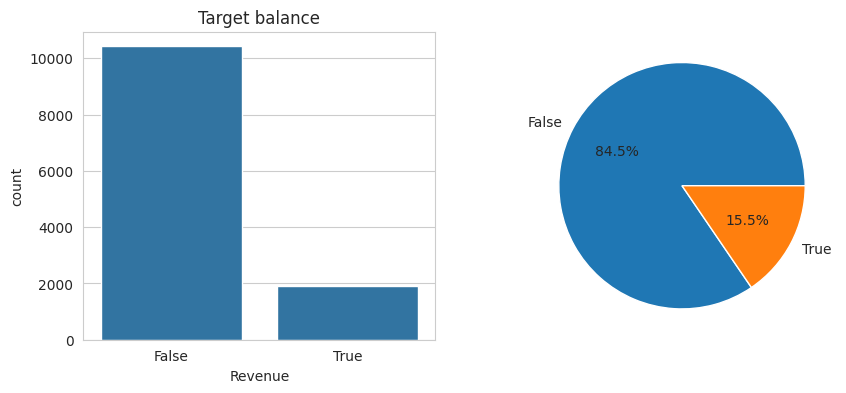

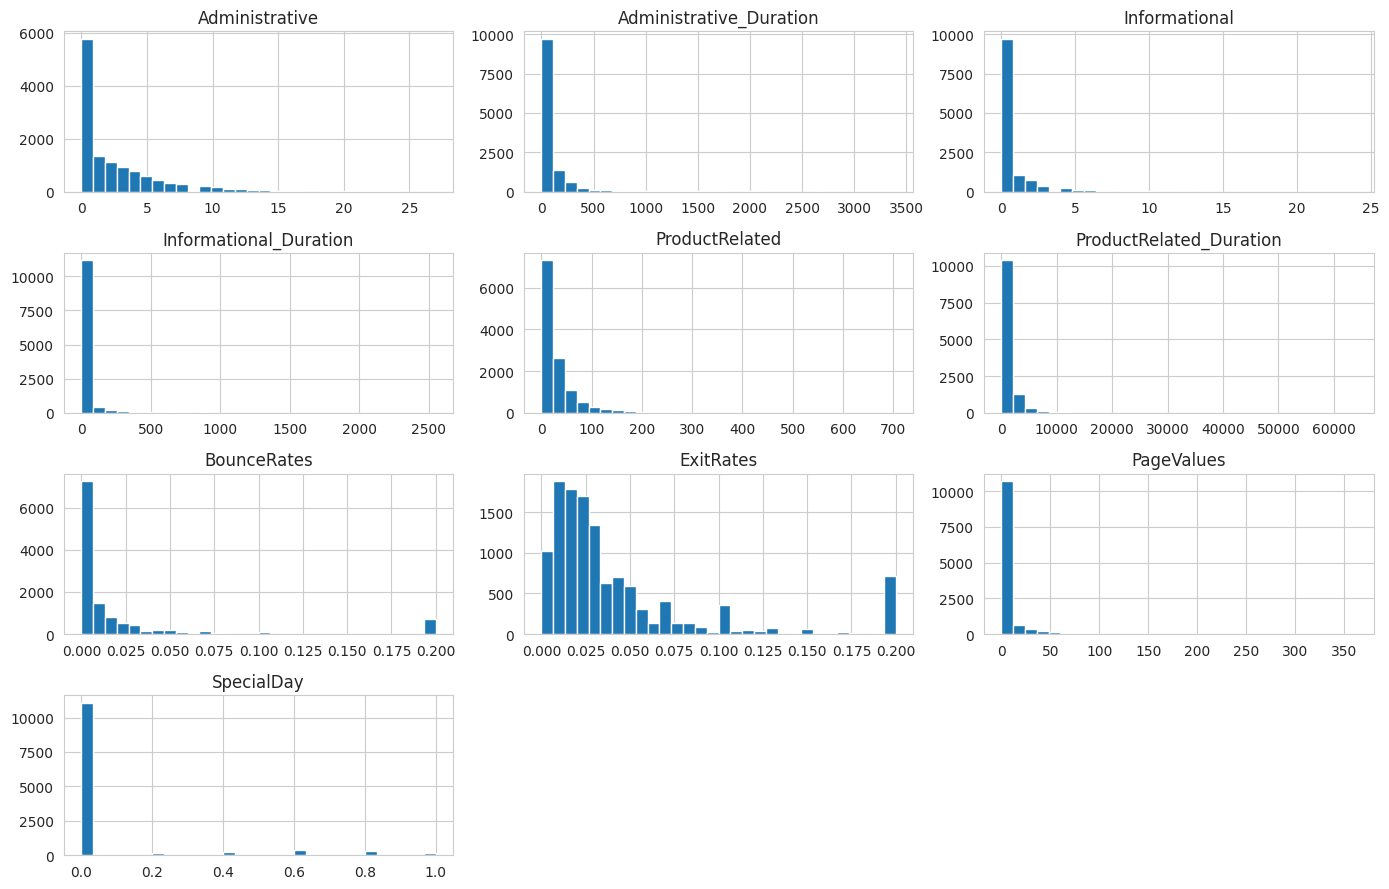

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x="Revenue", data=df, ax=ax[0]); ax[0].set_title("Target balance")
df["Revenue"].value_counts(normalize=True).plot.pie(autopct="%1.1f%%", ax=ax[1]); ax[1].set_ylabel("")
plt.show()

num_plot = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
df[num_plot].hist(bins=30, figsize=(14, 9))
plt.tight_layout(); plt.show()

### Bivariate (features vs. the target)

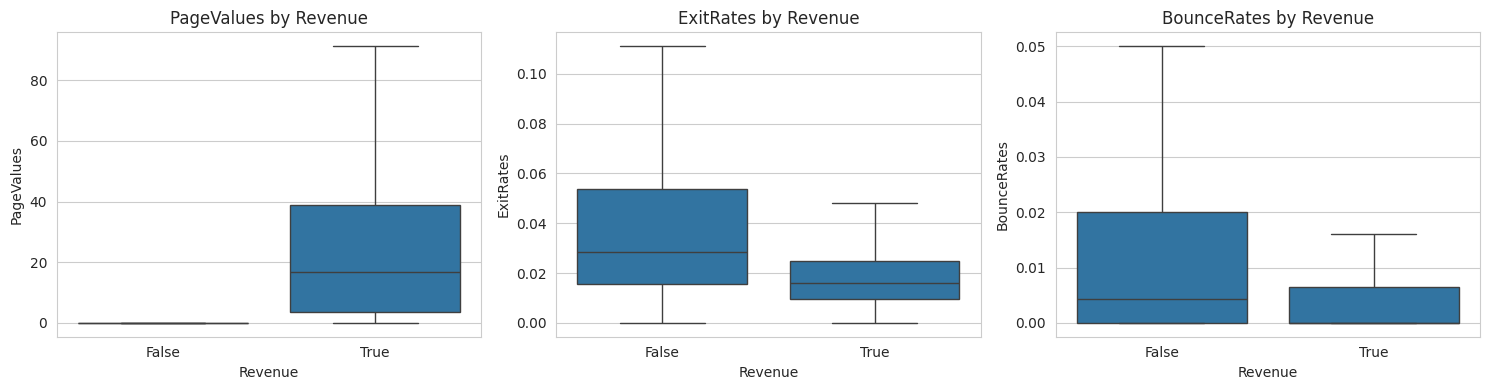

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["PageValues", "ExitRates", "BounceRates"]):
    sns.boxplot(x="Revenue", y=c, data=df, ax=a, showfliers=False)
    a.set_title(c + " by Revenue")
plt.tight_layout(); plt.show()

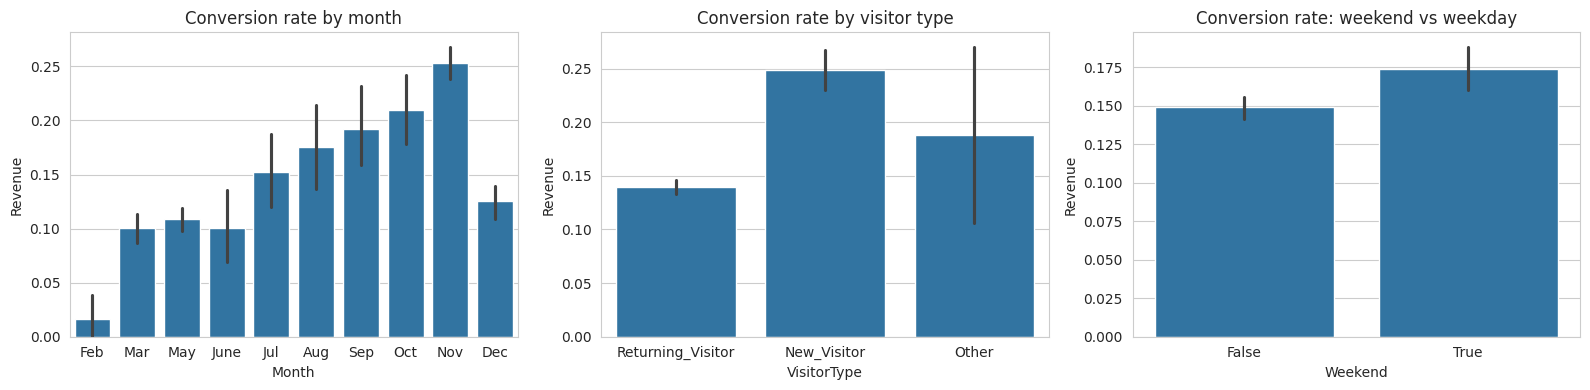

In [9]:
order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(x="Month", y="Revenue", data=df, order=order, ax=ax[0]); ax[0].set_title("Conversion rate by month")
sns.barplot(x="VisitorType", y="Revenue", data=df, ax=ax[1]); ax[1].set_title("Conversion rate by visitor type")
sns.barplot(x="Weekend", y="Revenue", data=df, ax=ax[2]); ax[2].set_title("Conversion rate: weekend vs weekday")
plt.tight_layout(); plt.show()

### Multivariate

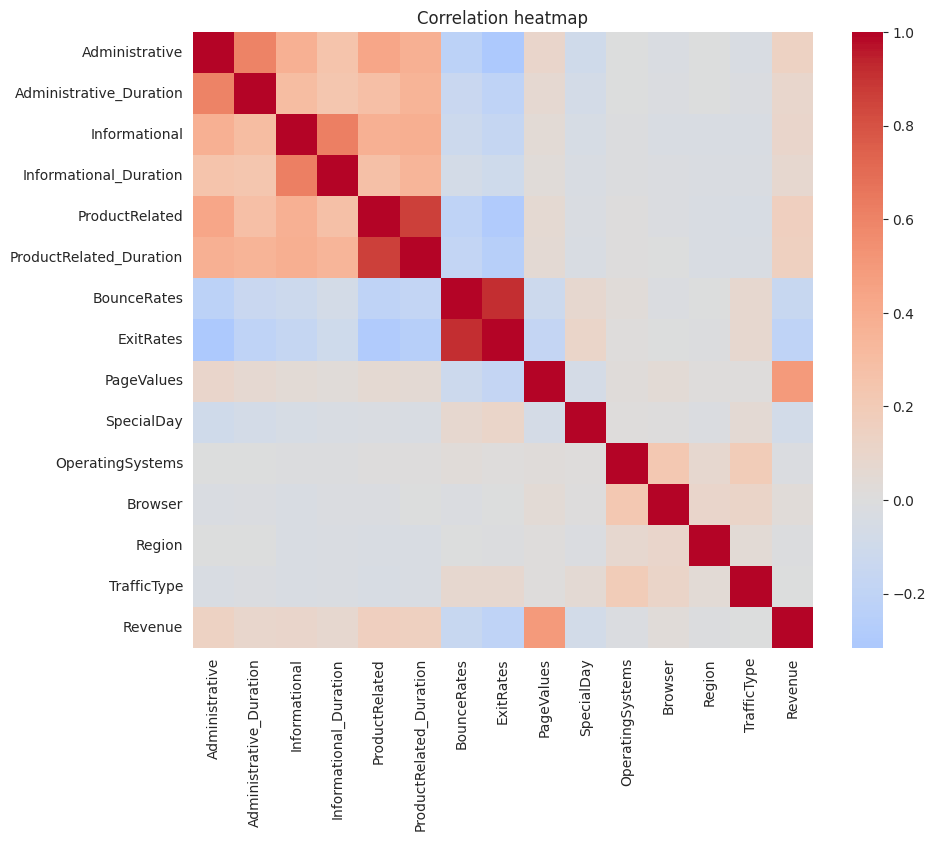

,Revenue
PageValues,0.493
ProductRelated,0.159
ProductRelated_Duration,0.152
Administrative,0.139
Informational,0.095
Administrative_Duration,0.094
Informational_Duration,0.070
Browser,0.024
TrafficType,-0.005
Region,-0.012


In [10]:
corr = df.select_dtypes("number").assign(Revenue=df["Revenue"].astype(int)).corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation heatmap"); plt.show()
corr["Revenue"].drop("Revenue").sort_values(ascending=False).round(3)

In [11]:
# Numbers to support your written insights
print("Overall conversion rate: %.1f%%" % (100 * df["Revenue"].mean()))
print("\nConversion by visitor type (%):")
print((100 * df.groupby("VisitorType")["Revenue"].mean()).round(1))
print("\nConversion by month (%):")
print((100 * df.groupby("Month")["Revenue"].mean()).reindex(order).round(1))
print("\nConversion by whether PageValues > 0 (%):")
print((100 * df.groupby(df["PageValues"] > 0)["Revenue"].mean()).round(1))

Overall conversion rate: 15.5%

Conversion by visitor type (%):
VisitorType
New_Visitor          24.9
Other                18.8
Returning_Visitor    13.9
Name: Revenue, dtype: float64

Conversion by month (%):
Month
Feb      1.6
Mar     10.1
May     10.9
June    10.1
Jul     15.3
Aug     17.6
Sep     19.2
Oct     20.9
Nov     25.4
Dec     12.5
Name: Revenue, dtype: float64

Conversion by whether PageValues > 0 (%):
PageValues
False     3.9
True     56.3
Name: Revenue, dtype: float64


## 4. Preprocessing and Pipeline
- Remove duplicate rows.
- Convert `Weekend` to 0/1 and treat the ID-like columns (`Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`) as **categorical**.
- **Split first** (80% train / 20% test, stratified), then fit scaling and encoding **inside a scikit-learn Pipeline** so nothing is learned from the test set (no leakage).
- Numeric features are scaled; categorical features are one-hot encoded (`handle_unknown="ignore"`).

### Key Insights
1. Only about **15.5%** of browsing sessions end in a purchase (`Revenue` = True), confirming that the target variable is highly imbalanced.
2. **`PageValues`** is by far the strongest predictor: sessions with `PageValues > 0` have a conversion rate of **56.3%**, compared to just **3.9%** for sessions with a value of zero.
3. New visitors exhibit a higher conversion rate (**24.9%**) compared to returning visitors (**13.9%**).
4. Conversion rates peak significantly in November at **25.4%** (likely due to holiday promotions and sales), while dropping to a low of **1.6%** in February.
5. Sessions that end in a purchase tend to exhibit lower exit and bounce rates (`ExitRates` and `BounceRates`), indicating that deeper engagement and browsing correspond to a much higher likelihood of completing a transaction.

In [12]:
data = df.drop_duplicates().reset_index(drop=True).copy()
data["Revenue"] = data["Revenue"].astype(int)
data["Weekend"] = data["Weekend"].astype(int)
print("Rows after removing duplicates:", len(data))

y = data["Revenue"]
X = data.drop(columns="Revenue")

cat_cols = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
num_cols = [c for c in X.columns if c not in cat_cols]
X[cat_cols] = X[cat_cols].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Buyers in train: %.1f%% | in test: %.1f%%" % (100 * y_train.mean(), 100 * y_test.mean()))

def make_pipe(model):
    pre = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    return Pipeline([("pre", pre), ("model", model)])

Rows after removing duplicates: 12205
Train: (9764, 17) | Test: (2441, 17)
Buyers in train: 15.6% | in test: 15.6%


## 5. Modeling and tuning
- **Baseline:** always predict the majority class ("no purchase").
- **Three algorithms:** Logistic Regression, Random Forest, Gradient Boosting.
- **Tuning:** `RandomizedSearchCV` with 3-fold stratified cross-validation, scored by ROC-AUC, **on the training set only**. Class imbalance is handled with `class_weight="balanced"` where available.

In [13]:
candidates = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced"),
        {"model__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
        {"model__n_estimators": [100, 200], "model__max_depth": [5, 10, 20, None],
         "model__min_samples_leaf": [1, 3, 5]}),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {"model__n_estimators": [100, 200, 300], "model__learning_rate": [0.03, 0.1],
         "model__max_depth": [2, 3, 4]}),
}
cv = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)

def scores(name, cv_auc, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    return {"Model": name, "CV ROC-AUC": cv_auc,
            "Test ROC-AUC": roc_auc_score(y_test, p),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "PR-AUC": average_precision_score(y_test, p)}

rows, fitted, best_params = [], {}, {}

base = make_pipe(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
rows.append(scores("Baseline (majority class)", np.nan, base.predict_proba(X_test)[:, 1]))

for name, (model, grid) in candidates.items():
    print("Tuning", name, "...")
    n_iter = min(4, int(np.prod([len(v) for v in grid.values()])))
    search = RandomizedSearchCV(make_pipe(model), grid, n_iter=n_iter, scoring="roc_auc",
                                cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train, y_train)
    fitted[name] = (search.best_estimator_, search.best_score_)
    best_params[name] = search.best_params_
    rows.append(scores(name, search.best_score_, search.best_estimator_.predict_proba(X_test)[:, 1]))

results = pd.DataFrame(rows).round(3)
results

Tuning Logistic Regression ...
Tuning Random Forest ...
Tuning Gradient Boosting ...


,Model,CV ROC-AUC,Test ROC-AUC,Precision,Recall,F1,PR-AUC
0,Baseline (majority class),NaN,0.500,0.000,0.000,0.000,0.156
1,Logistic Regression,0.899,0.911,0.512,0.793,0.622,0.663
2,Random Forest,0.926,0.930,0.561,0.827,0.669,0.727
3,Gradient Boosting,0.930,0.937,0.719,0.615,0.663,0.740


In [14]:
for k, v in best_params.items():
    print(k, "->", v)

Logistic Regression -> {'model__C': 0.1}
Random Forest -> {'model__n_estimators': 100, 'model__min_samples_leaf': 5, 'model__max_depth': 20}
Gradient Boosting -> {'model__n_estimators': 300, 'model__max_depth': 4, 'model__learning_rate': 0.03}


## 6. Evaluation on the untouched test set
The best model is chosen by **cross-validation score on the training data** (not by looking at the test set).

In [15]:
best_name = max(fitted, key=lambda k: fitted[k][1])
best_model = fitted[best_name][0]
p_test = best_model.predict_proba(X_test)[:, 1]
print("Best model:", best_name)
print("\nClassification report at threshold 0.5:\n")
print(classification_report(y_test, (p_test >= 0.5).astype(int), target_names=["No purchase", "Purchase"]))

Best model: Gradient Boosting

Classification report at threshold 0.5:

              precision    recall  f1-score   support

 No purchase       0.93      0.96      0.94      2059
    Purchase       0.72      0.62      0.66       382

    accuracy                           0.90      2441
   macro avg       0.82      0.79      0.80      2441
weighted avg       0.90      0.90      0.90      2441



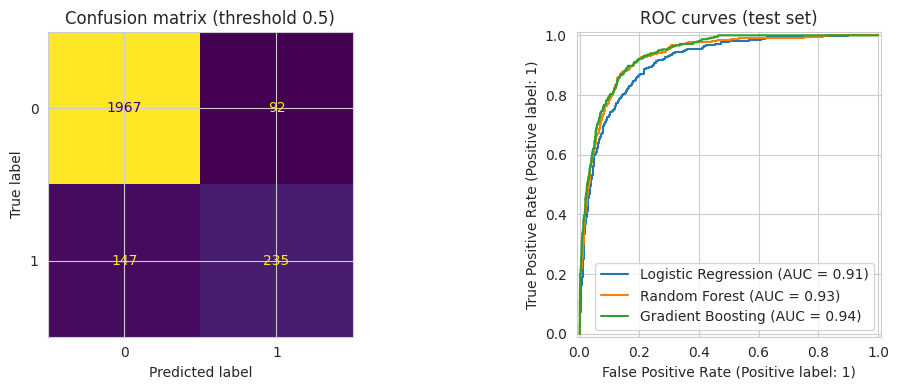

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (threshold 0.5)")
for n, (m, _) in fitted.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=ax[1], name=n)
ax[1].set_title("ROC curves (test set)")
plt.tight_layout(); plt.show()

### Choosing the decision threshold
The default 0.5 is not necessarily the best business choice. A **lower threshold** catches more buyers (higher recall) but flags more non-buyers (lower precision). The table below lets you pick a threshold and justify it.

In [17]:
thr = pd.DataFrame({
    "Threshold": [0.1, 0.2, 0.3, 0.4, 0.5, 0.6],
})
thr["Precision"] = [precision_score(y_test, (p_test >= t).astype(int), zero_division=0) for t in thr["Threshold"]]
thr["Recall"] = [recall_score(y_test, (p_test >= t).astype(int)) for t in thr["Threshold"]]
thr["Flagged as likely buyer (%)"] = [100 * (p_test >= t).mean() for t in thr["Threshold"]]
thr.round(3)

,Threshold,Precision,Recall,Flagged as likely buyer (%)
0,0.1,0.481,0.901,29.291
1,0.2,0.573,0.812,22.163
2,0.3,0.636,0.767,18.886
3,0.4,0.685,0.702,16.018
4,0.5,0.719,0.615,13.396
5,0.6,0.756,0.526,10.897


### Error analysis

In [18]:
err = X_test.assign(y=y_test, p=p_test)
fn = err[(err.y == 1) & (err.p < 0.5)]
fp = err[(err.y == 0) & (err.p >= 0.5)]
print("Missed buyers (false negatives):", len(fn), "of", int(y_test.sum()))
print("False alarms (false positives): ", len(fp), "of", int((y_test == 0).sum()))

print("\nMissed buyers: key features")
print(fn[["PageValues", "ExitRates", "BounceRates"]].describe().round(3))
print("\nCorrectly caught buyers: key features")
print(err[(err.y == 1) & (err.p >= 0.5)][["PageValues", "ExitRates", "BounceRates"]].describe().round(3))

Missed buyers (false negatives): 147 of 382
False alarms (false positives):  92 of 2059

Missed buyers: key features
       PageValues  ExitRates  BounceRates
count     147.000    147.000      147.000
mean        6.986      0.027        0.009
std        11.563      0.022        0.020
min         0.000      0.003        0.000
25%         0.000      0.014        0.000
50%         0.132      0.023        0.005
75%        10.494      0.032        0.012
max        78.198      0.200        0.200

Correctly caught buyers: key features
       PageValues  ExitRates  BounceRates
count     235.000    235.000      235.000
mean       39.497      0.015        0.002
std        33.898      0.012        0.006
min         1.114      0.000        0.000
25%        17.110      0.007        0.000
50%        31.758      0.012        0.000
75%        52.083      0.019        0.002
max       214.307      0.084        0.048


### Which features matter most? (permutation importance on the test set)


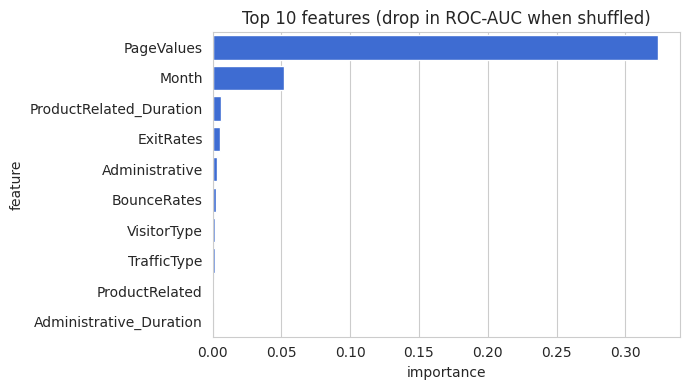

In [19]:
imp = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                             n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp_df = (pd.DataFrame({"feature": X_test.columns, "importance": imp.importances_mean})
          .sort_values("importance", ascending=False).head(10))
plt.figure(figsize=(7, 4))
sns.barplot(x="importance", y="feature", data=imp_df, color="#2563eb")
plt.title("Top 10 features (drop in ROC-AUC when shuffled)")
plt.tight_layout(); plt.show()

In [20]:
# Display the top 10 features in order of importance
display(imp_df.reset_index(drop=True))

,feature,importance
0,PageValues,0.323484
1,Month,0.051635
2,ProductRelated_Duration,0.006363
3,ExitRates,0.005414
4,Administrative,0.003457
5,BounceRates,0.002201
6,VisitorType,0.002081
7,TrafficType,0.001449
8,ProductRelated,0.001247
9,Administrative_Duration,0.000125


## 7. Business insight and recommendations

**What the results mean**
- The best model (**Gradient Boosting**) reaches a test ROC-AUC of **0.937**, far above the baseline (0.50), so browsing behavior really does predict purchases.
- At threshold 0.5 it catches **61.5%** of buyers (235 of 382) with **71.9%** precision. At a lower threshold of **0.3** it catches **76.7%** of buyers with **63.6%** precision, so the store reaches more real buyers at the cost of more false alarms.
- The most important signals are **`PageValues`** (by a very wide margin), followed by **`Month`** and **`ProductRelated_Duration`**.

**What the store should do**
1. Visitors with a **high** purchase probability (0.5 or more): show nothing, because they are likely to buy without a discount.
2. Visitors in the **middle** range: show a coupon, because they are undecided and an incentive may tip them.
3. Visitors with a **low** probability who are still browsing: offer the chat assistant to find out what they need.
4. Choose the thresholds from the threshold table based on the cost of a coupon versus the value of a sale. The web app lets the store change them.

**Limitations**
- Data comes from one store and one period, so the model may not generalize to other stores or seasons.
- `PageValues` is computed from past behavior and must be available in real time for the model to work in production.
- The model missed 147 of 382 buyers at threshold 0.5. These buyers had low `PageValues` (average 7.0, compared with 39.5 for the buyers it caught), so buyers with no valuable browsing history are hard to catch.
- The model estimates probability. It does not prove that a coupon causes a purchase; that needs an A/B test.

In [23]:
import sklearn
print(sklearn.__version__)

1.9.1


## 8. Save the pipeline for the web app

In [21]:
joblib.dump(best_model, "model.joblib")
defaults = {c: float(X_train[c].median()) for c in num_cols}
defaults.update({c: X_train[c].mode()[0] for c in cat_cols})
json.dump({"defaults": defaults, "columns": list(X.columns), "best_model": best_name},
          open("app_config.json", "w"), indent=2)
results.to_csv("results.csv", index=False)
print("Saved: model.joblib, app_config.json, results.csv")

 #Colab only: uncomment to download the files to your computer
from google.colab import files
for f in ["model.joblib", "app_config.json", "results.csv"]:
    files.download(f)

Saved: model.joblib, app_config.json, results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Dataset credit:** Sakar, C. and Kastro, Y. (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/468

In [22]:
import sklearn, pandas, numpy
print(sklearn.__version__, pandas.__version__, numpy.__version__)

1.9.1 2.2.3 2.4.6
